In [1]:
import sys
sys.path.append('../src')

from preprocess import load_data, clean_data, encode_onehot, split_data

df = load_data('../data/telco_churn.csv')
df = clean_data(df)
df_encoded = encode_onehot(df)
X_train, X_test, y_train, y_test = split_data(df_encoded)

In [3]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [5]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [6]:
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

In [7]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report
)

In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC:", average_precision_score(y_test, y_proba))
print(classification_report(y_test, y_pred))

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1: 0.6136125654450262
ROC-AUC: 0.8417318969748638
PR-AUC: 0.6331333997866266
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



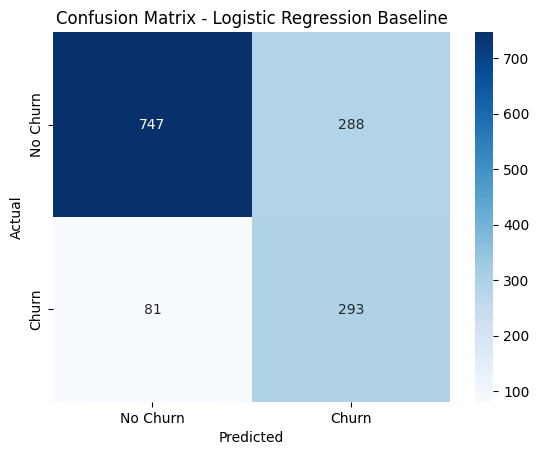

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression Baseline')
plt.show()

In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid_lr = {
    'C': [0.01, 0.1, 1]
}

lr_base = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

grid_lr = GridSearchCV(lr_base, param_grid_lr, scoring='roc_auc', cv=5, n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

print("Best LR params:", grid_lr.best_params_)
print("Best LR CV ROC-AUC:", grid_lr.best_score_)

lr_tuned = grid_lr.best_estimator_
y_proba_lr_tuned = lr_tuned.predict_proba(X_test_scaled)[:, 1]
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba_lr_tuned))

Best LR params: {'C': 1}
Best LR CV ROC-AUC: 0.8453313819608053
Test ROC-AUC: 0.8417318969748638


In [23]:
y_pred_lr_tuned = lr_tuned.predict(X_test_scaled)
y_proba_lr_tuned = lr_tuned.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_lr_tuned))
print("Precision:", precision_score(y_test, y_pred_lr_tuned))
print("Recall:", recall_score(y_test, y_pred_lr_tuned))
print("F1:", f1_score(y_test, y_pred_lr_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_lr_tuned))
print("PR-AUC:", average_precision_score(y_test, y_proba_lr_tuned))
print(classification_report(y_test, y_pred_lr_tuned, target_names=['No Churn', 'Churn']))

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1: 0.6136125654450262
ROC-AUC: 0.8417318969748638
PR-AUC: 0.6331333997866266
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

